### EXPERIMENT 1: DIGITAL IMAGE REPRESENTATION
Objective: Understand binary, grayscale, and RGB images as NumPy arrays.

Tasks:
 1. Examine image shape, dimensions, data type, and intensity range.
 2. Compare binary (1-bit), grayscale (8-bit), and RGB (24-bit) images.

Question: How do these image representations differ?


Binary Image
Shape: (200, 200)
Dimensions: 2
Data type: bool
Intensity range: False True

Grayscale Image
Shape: (512, 512)
Dimensions: 2
Data type: uint8
Intensity range: 0 255

RGB Image
Shape: (370, 371, 3)
Dimensions: 3
Data type: uint8
Intensity range: 0 255


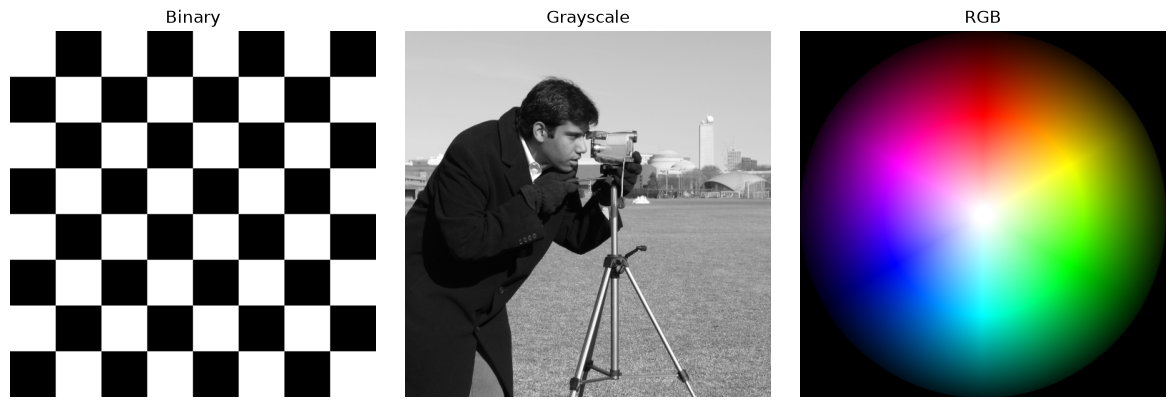

In [12]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt

gray = data.camera()
gray2 = data.checkerboard()
binary = gray2 > 127
rgb = data.colorwheel()

images = {
    "Binary": binary,
    "Grayscale": gray,
    "RGB": rgb
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (name, img) in zip(axes, images.items()):
    print(f"\n{name} Image")
    print("Shape:", img.shape)
    print("Dimensions:", img.ndim)
    print("Data type:", img.dtype)
    print("Intensity range:", img.min(), img.max())

    ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 2: PIXEL REPRESENTATION

Objective: Explore pixel coordinates and intensity values.

Tasks:
 1. Examine the intensity of a selected pixel.
 2. Display a small image region as a numerical matrix.

Question: What do the rows and columns represent?

Pixel intensity: 211

5 x 5 pixel region:
[[211 211 212 210 211]
 [211 211 211 210 210]
 [211 211 212 211 211]
 [211 211 211 211 211]
 [212 211 211 211 210]]


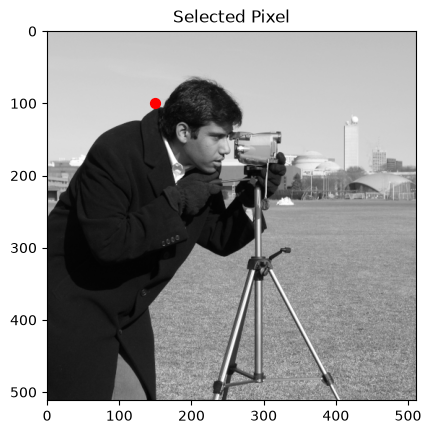

In [13]:
row, col = 100, 150

print("Pixel intensity:", gray[row, col])
print("\n5 x 5 pixel region:")
print(gray[row:row+5, col:col+5])

plt.imshow(gray, cmap="gray")
plt.scatter(col, row, color="red", s=50)
plt.title("Selected Pixel")
plt.show()

### EXPERIMENT 3: SPATIAL SAMPLING
Objective: Investigate the effect of sampling density.

Tasks:
 1. Compare images sampled at different spatial intervals.
 2. Observe the loss of spatial detail as sampling becomes coarser.

Question: How does undersampling affect image quality?

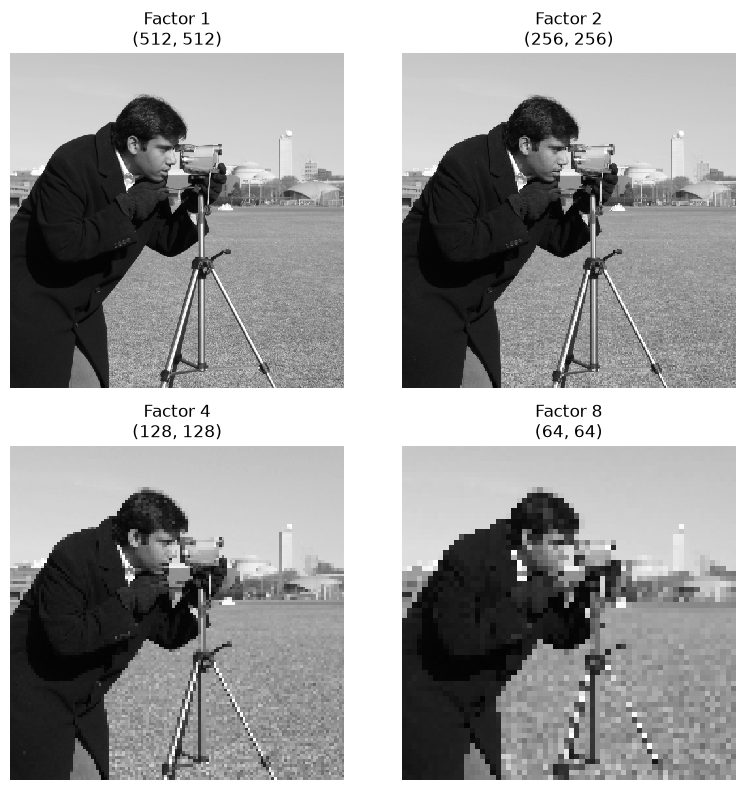

In [14]:
factors = [1, 2, 4, 8]

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for ax, factor in zip(axes.flat, factors):
    sampled = gray[::factor, ::factor]

    ax.imshow(sampled, cmap="gray", vmin=0, vmax=255,
              interpolation="nearest")
    ax.set_title(f"Factor {factor}\n{sampled.shape}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 4: INTENSITY QUANTIZATION

Objective: Investigate the effect of bit depth on image appearance.

Quantization levels: L = 2^b, where b is the number of bits.

Tasks:

 1. Compare images represented using different intensity levels.
 2. Observe the loss of tonal detail as bit depth decreases.

Question: How do spatial sampling and quantization differ?

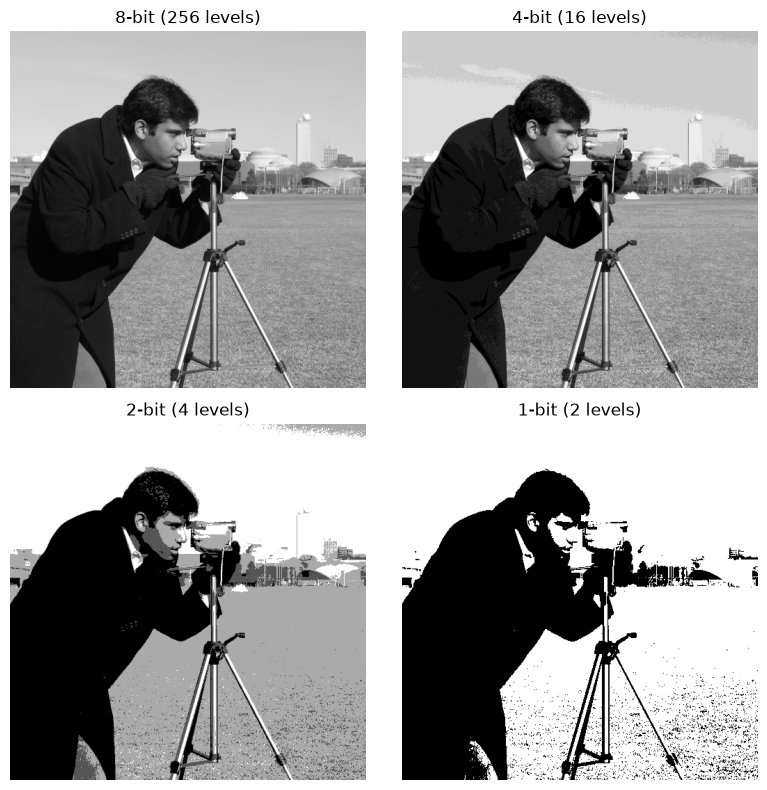

In [15]:
bits = [8, 4, 2, 1]

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for ax, b in zip(axes.flat, bits):
    levels = 2**b
    quantized = np.floor(gray.astype(float) / 256 * levels)
    quantized = quantized * (255 / (levels - 1))

    ax.imshow(quantized, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{b}-bit ({levels} levels)")
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 6: RGB COLOR CHANNELS
Objective: Understand how color images are represented.

Tasks:
 1. Extract the red, green, and blue channels.
 2. Display each channel as a grayscale intensity image.

 Question: Why do different colors produce different channel intensities?

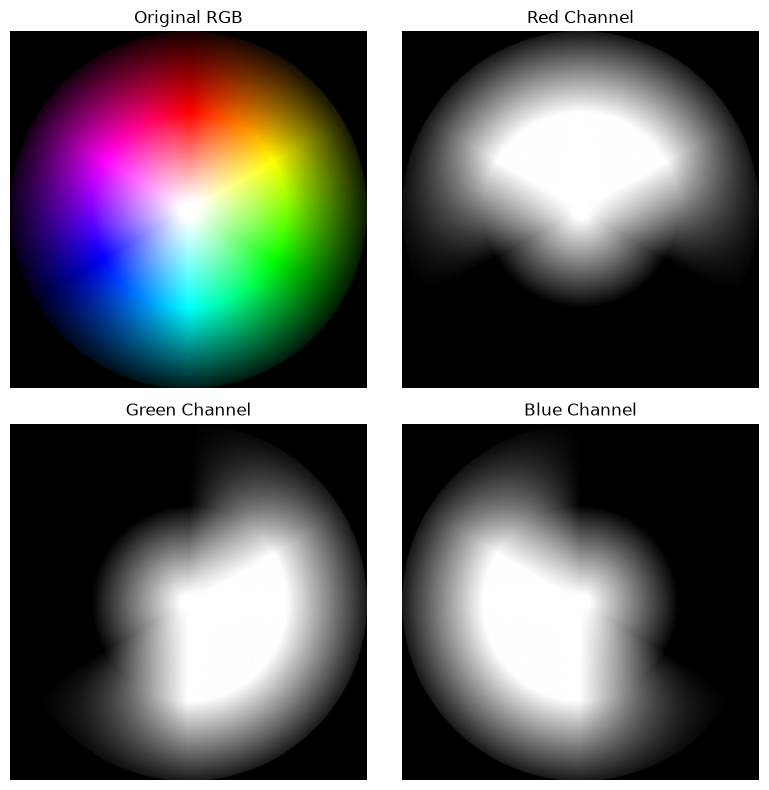

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(8, 8))

axes[0, 0].imshow(rgb)
axes[0, 0].set_title("Original RGB")

for ax, i, name in zip(
    axes.flat[1:],
    range(3),
    ["Red", "Green", "Blue"]
):
    ax.imshow(rgb[:, :, i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{name} Channel")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()